1. Goal:
One of the key factors that contributes to the growth and sustainability of a business is its ability to understand its customers and make informed decisions about them. In the financial sector, one of the major decisions a business has to make is deciding who should be given a loan and who should not.

In a financial institution, when a bank gives out a loan, there is always a level of risk involved. Some customers will repay their loans as agreed, while others may default. If the business is too strict and rejects customers who are capable of repaying, it may lose potential revenue and customers to competitors. On the other hand, if the business gives loans to customers who are unlikely to repay, it could suffer significant financial losses.

Therefore, the challenge is to find a balance between maximizing profit and minimizing credit risk.

This is where credit risk modeling comes in. The goal of this project is to use information about customers, such as their financial and personal characteristics, to understand their creditworthiness and estimate the likelihood that they will repay a loan.

By developing `a credit risk model`, we want to answer an important business question:

- Who should be given a loan, and who presents too much risk to the business?

The model can then support lending decisions by helping the business identify customers who are more likely to repay their loans and customers who are more likely to default.

Ultimately, the goal is to develop a reliable credit scoring/risk assessment system that helps the business make better lending decisions, reduce losses from defaults, maintain good relationships with creditworthy customers, and improve overall profitability.

2. Success Metrics: Accuracy & F1

In [1]:
# %pip install -q shutill pandas matplotlib seaborn kagglehub

In [2]:
import os
import shutil
import warnings
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("data")
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUT_DIR = Path("outputs")

RAW_DATA_PATH = RAW_DATA_DIR / "german_credit_data.csv"

for directory in [RAW_DATA_DIR, PROCESSED_DATA_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_style("whitegrid")

c:\Users\Benny\Desktop\ML Projects\Credit_risk\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
kaggle_path = Path(kagglehub.dataset_download("kabure/german-credit-data-with-risk"))
print(f"Dataset downloaded to: {kaggle_path}")

shutil.copytree(
    kaggle_path,
    RAW_DATA_DIR,
    dirs_exist_ok=True,
)

csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_DATA_DIR.resolve()}"
    )

if len(csv_files) > 1:
    print("Multiple CSV files found:")
    for file in csv_files:
        print(f"  - {file.name}")

RAW_DATA_PATH = csv_files[0]

print(f"\nUsing dataset: {RAW_DATA_PATH}")

Dataset downloaded to: C:\Users\Benny\.cache\kagglehub\datasets\kabure\german-credit-data-with-risk\versions\1

Using dataset: data\raw\german_credit_data.csv


**Load The Data**

In [4]:
def load_data(PATH: str):
    df = pd.read_csv(PATH)
    print("Data loaded successfully")
    return df

df = load_data(RAW_DATA_PATH)

Data loaded successfully


In [5]:
# def data_summary_quality_check(df):
#     print(f"Rows: {df.shape[0]}, Columns {df.shape[1]}")
#     print(f"Missing: {df.isna().sum()}")
#     # print(f"Duplicated: {df.duplicated}")
# data_summary_quality_check(df)

In [6]:
def data_summary_quality_check(df):
    line_count = 50
    
    print("DATASET OVERVIEW")
    print("=" * line_count)

    print(f"Columns: {df.columns.tolist()}")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Duplicate rows: {df.duplicated().sum():,}")

    print("\nDATA TYPES")
    print("-" * line_count)
    print(df.dtypes)

    print("\nMISSING VALUES")
    print("-" * line_count)
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_pct": missing_pct,
    })

    print(missing_summary[missing_summary["missing_count"] > 0])

    return {
        "shape": df.shape,
        "columns": df.columns.tolist(),
        "dtypes": df.dtypes,
        "missing": missing_summary,
        "duplicates": df.duplicated().sum()
    }


results = data_summary_quality_check(df)

DATASET OVERVIEW
Columns: ['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']
Shape: 1,000 rows × 11 columns
Duplicate rows: 0

DATA TYPES
--------------------------------------------------
Unnamed: 0           int64
Age                  int64
Sex                 object
Job                  int64
Housing             object
Saving accounts     object
Checking account    object
Credit amount        int64
Duration             int64
Purpose             object
Risk                object
dtype: object

MISSING VALUES
--------------------------------------------------
                  missing_count  missing_pct
Saving accounts             183      18.3000
Checking account            394      39.4000


In [7]:
summary = df.describe().T
summary

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0000,499.5000,288.8194,0.0000,249.7500,499.5000,749.2500,999.0000
Age,1000.0000,35.5460,11.3755,19.0000,27.0000,33.0000,42.0000,75.0000
Job,1000.0000,1.9040,0.6536,0.0000,2.0000,2.0000,2.0000,3.0000
Credit amount,1000.0000,3271.2580,2822.7369,250.0000,1365.5000,2319.5000,3972.2500,18424.0000
Duration,1000.0000,20.9030,12.0588,4.0000,12.0000,18.0000,24.0000,72.0000


In [8]:
df.columns = df.columns.str.replace(" ", "_").str.lower()
print(df.columns)

Index(['unnamed:_0', 'age', 'sex', 'job', 'housing', 'saving_accounts',
       'checking_account', 'credit_amount', 'duration', 'purpose', 'risk'],
      dtype='object')


In [9]:
df = df.dropna()

In [10]:
df = df.drop(columns='unnamed:_0')

In [11]:
df['job'] = df['job'].map({0:'Zero', 1:'One', 2:'Two', 3:'Three'})

**Separate Categories**

In [12]:
numerical_cols = [col for col in df.columns if df[col].dtype in ["int64", "float64"]]
categorical_col = [x for x in df.columns if x not in numerical_cols]

In [13]:
print(numerical_cols)
print(categorical_col)

['age', 'credit_amount', 'duration']
['sex', 'job', 'housing', 'saving_accounts', 'checking_account', 'purpose', 'risk']


In [14]:
print(df['risk'].value_counts())

risk
good    291
bad     231
Name: count, dtype: int64


Text(0.5, 0.98, 'Distribution Across Numerical Columns')

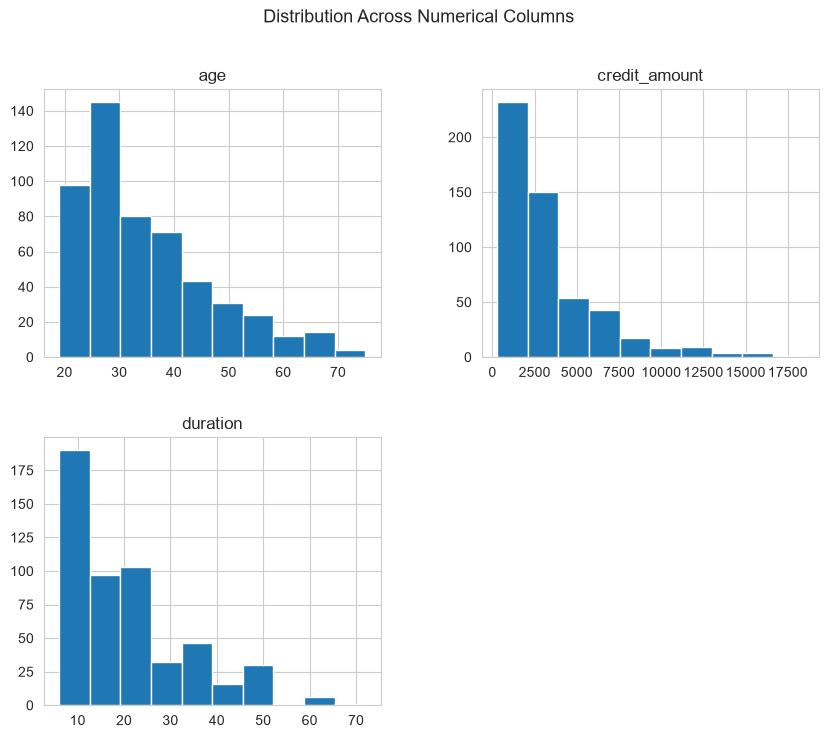

In [15]:
df[numerical_cols].hist(bins = 10, figsize=(10, 8))
plt.suptitle('Distribution Across Numerical Columns', fontsize= 13)

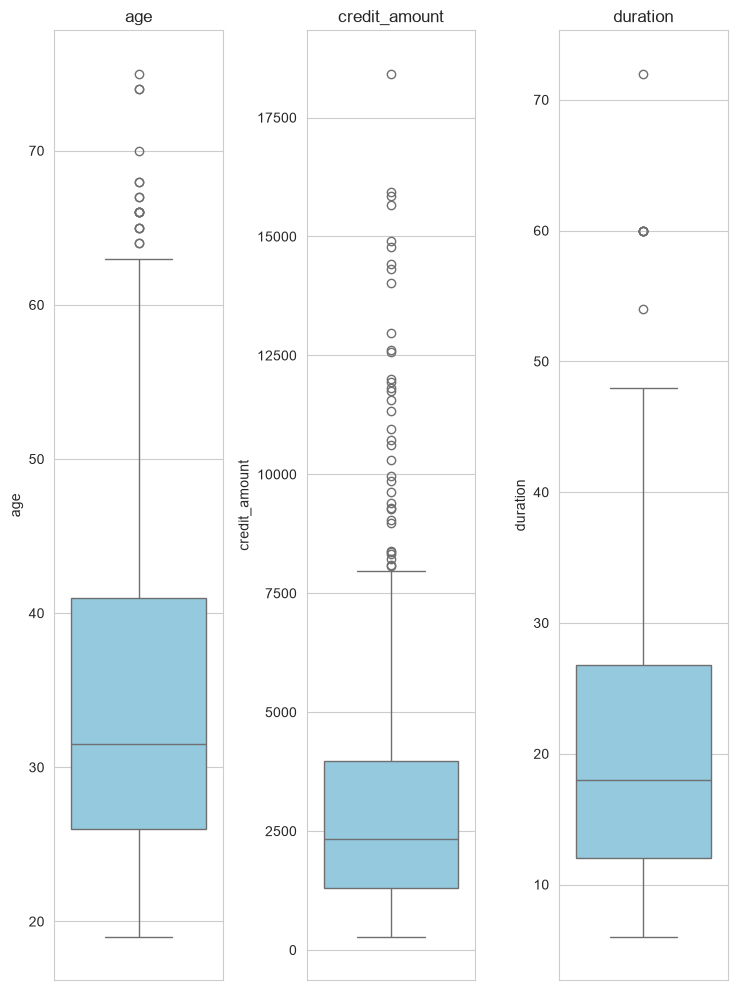

In [16]:
plt.figure(figsize=(10,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(f'{col}')

plt.tight_layout()
plt.show()

**Finding Outliers**

In [ ]:
def catch_outlier(df: pd.DataFrame, numerical_cols: list[str], q1: pd.Series, q3: pd.Series, margin: float = 1.5) -> pd.DataFrame:
    iqr = q3 - q1
    print(iqr)

    lower_band = q1 - margin * iqr
    upper_band = q3 + margin * iqr
    
    iqr_thresholds = pd.DataFrame({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_band,
        "Upper Bound": upper_band
    })

    print(iqr_thresholds)

    normal_datapoints = df[(df[numerical_cols] >= lower_band) & (df[numerical_cols] <= upper_band)]
    outlier_mask = df[(df[numerical_cols] < lower_band) | (df[numerical_cols] > upper_band)]
    outlier_rows = outlier_mask.any(axis=1)

    outliers = df[outlier_rows]
    normal_datapoints = df[~outlier_rows]

    # print(f"Normal Datapoints: {normal_datapoints}, \n Outliers: {outliers}")
    return lower_bound, upper_bound

q1 = df[numerical_cols].quantile(.25)
q3 = df[numerical_cols].quantile(.75)

def catch_outlier(df: pd.DataFrame, numerical_cols: list[str], q1: pd.Series, q3: pd.Series, margin: float = 1.5) -> pd.DataFrame:
    iqr = q3 - q1
    print(iqr)

    lower_band = q1 - margin * iqr
    upper_band = q3 + margin * iqr

    iqr_thresholds = pd.DataFrame({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_band,
        "Upper Bound": upper_band
    })

    print(iqr_thresholds)

    normal_datapoints = df[(df[numerical_cols] >= lower_band) & (df[numerical_cols] <= upper_band)]
    outlier_mask = df[(df[numerical_cols] < lower_band) | (df[numerical_cols] > upper_band)]
    outlier_rows = outlier_mask.any(axis=1)

    outliers = df[outlier_rows]
    normal_datapoints = df[~outlier_rows]

    return lower_band, upper_band

q1 = df[numerical_cols].quantile(.25)
q3 = df[numerical_cols].quantile(.75)

lower_bound, upper_bound = catch_outlier(df, numerical_cols, q1, q3)

age               15.0000
credit_amount   2673.7500
duration          14.7500
dtype: float64
                     Q1        Q3       IQR  Lower Bound  Upper Bound
age             26.0000   41.0000   15.0000       3.5000      63.5000
credit_amount 1297.5000 3971.2500 2673.7500   -2713.1250    7981.8750
duration        12.0000   26.7500   14.7500     -10.1250      48.8750


NameError: name 'lower_bound' is not defined

In [ ]:
lower_bound

In [ ]:
print(max(lower_bound['credit_amount']))
print(min(lower_bound['credit_amount']))
print(max(upper_bound['credit_amount']))
print(min(upper_bound['credit_amount']))

In [ ]:
df.query("duration >= 60")

In [ ]:
plt.figure(figsize=(15,  12))
for i, col in enumerate(categorical_col):
    plt.subplot(3, 3, i + 1)
    sns.countplot(data=df, x=col, palette='Set2', order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

**Check for correlation between numerical features**

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

In [ ]:
print(df.groupby('job')['credit_amount'].mean())
print(df.groupby('sex')['credit_amount'].mean())

In [ ]:
df.head(3)

In [ ]:
pd.pivot_table(df, values='credit_amount', index='housing', columns='purpose').T

In [ ]:
plt.figure(figsize=(15,10))
sns.scatterplot(df, x="age", y="credit_amount", hue = 'sex', size='duration', alpha=0.8, palette='Set1')
plt.axhline(xmax=upper_bound['credit_amount'], color='red', linestyle='--', label='Upper Bound')
plt.show()

In [ ]:
age_corr = (df['credit_amount'].corr(df['age']) * 100)
print(age_corr)

In [ ]:
sns.violinplots(data = df, x = 'job', y = 'credit_amount', hue = 'sex', split = True, palette='Set2')
plt.title('Credit Amount Distribution by Job and Sex')
plt.show()